# EmbeddingGemma2 accuracy evaluation

Evaluates `model/wdp-embeddinggemma2` (trained in `EmbeddingGemma2Colab.ipynb`) on the held-out `test_l1` set.
Test labels `UP`/`DOWN` map to the training labels `WSTL_UP`/`WSTL_DOWN`; the test set has no `NOISE`,
so accuracy is reported both over all 5 outputs and with `NOISE` masked out of the argmax.

In [1]:
import os, inspect, torch, torch.nn as nn, torch.nn.functional as F
import torchaudio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoConfig, AutoModel, AutoFeatureExtractor
from peft import PeftModel
from sklearn.metrics import classification_report, balanced_accuracy_score

MODEL_DIR = "/Users/dkohlsdorf/Documents/continuous_profile_hmm/model/wdp-embeddinggemma2"
AUDIO     = "/Users/dkohlsdorf/Documents/audio/test_l1/l1_test.wav"
LABELS    = "/Users/dkohlsdorf/Documents/audio/test_l1/l1_test.csv"
BATCH     = 64

ck          = torch.load(f"{MODEL_DIR}/wdp-heads.pt", map_location="cpu")
CFG         = ck["config"]
MID         = CFG["base_model"]
SR          = CFG["sr"]
WIN         = CFG["win"]
NUM_CLASSES = CFG["num_classes"]
PROJ_DIM    = CFG["proj_dim"]
LABEL_MAP   = CFG["label_map"]
DEVICE      = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
torch.set_num_threads(os.cpu_count())
CFG, DEVICE

W1027 11:07:44.854000 75122 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


({'base_model': 'google/embeddinggemma-2',
  'sr': 16000,
  'win': 5120,
  'num_classes': 5,
  'proj_dim': 128,
  'margin': 0.3,
  'label_map': {2: 'WSTL_DOWN',
   1: 'WSTL_UP',
   4: 'BURST',
   3: 'ECHO',
   0: 'NOISE'}},
 'mps')

In [2]:
# ---- keep only the audio tower (no vision, no text) ----
cfg = AutoConfig.from_pretrained(MID)
cfg.vision_config = None
base = AutoModel.from_pretrained(MID, config=cfg, torch_dtype=torch.float32)
audio_tower = next(m for m in base.modules() if type(m).__name__.endswith("AudioModel"))
del base

feature_extractor = AutoFeatureExtractor.from_pretrained(MID)
TOWER_TAKES_MASK = len(inspect.signature(audio_tower.forward).parameters) > 1

audio_tower = PeftModel.from_pretrained(audio_tower, f"{MODEL_DIR}/audio-lora")

def run_tower(tower, x):
    dev = next(tower.parameters()).device
    f = feature_extractor(list(x.detach().cpu().numpy()), sampling_rate=SR, return_tensors="pt")
    feats = f["input_features"].to(dev)
    out = (tower(feats, f["input_features_mask"].to(dev))
           if TOWER_TAKES_MASK else tower(feats))
    return out[0] if isinstance(out, tuple) else out.last_hidden_state


class WDPModel(nn.Module):
    def __init__(self, tower, num_classes, proj_dim=PROJ_DIM, p_drop=0.1):
        super().__init__()
        self.encoder = tower
        with torch.no_grad():                                   # measure tower width once
            d = run_tower(tower, torch.zeros(1, WIN)).shape[-1]
        self.head_embedding = nn.Linear(d, proj_dim)
        self.classifier = nn.Sequential(nn.Dropout(p_drop), nn.Linear(proj_dim, num_classes))

    def embed(self, x):                                         # (B, WIN) -> (B, 128)
        return self.head_embedding(run_tower(self.encoder, x).mean(1).float())

    def forward(self, x):
        z = self.embed(x)
        return {"classifications": self.classifier(z), "embeddings": F.normalize(z, dim=-1)}

clf = WDPModel(audio_tower, NUM_CLASSES)
clf.head_embedding.load_state_dict(ck["head_embedding"])
clf.classifier.load_state_dict(ck["classifier"])
clf = clf.to(DEVICE).eval()

Loading weights:   0%|          | 0/1165 [00:00<?, ?it/s]

/opt/anaconda3/lib/python3.13/site-packages/peft/config.py:220: UserWarning: Unexpected keyword arguments ['kasa_config', 'monteclora_config', 'velora_config'] for class LoraConfig, these are ignored. This probably means that you're loading a configuration file that was saved using a higher version of the library and additional parameters have been introduced since. It is highly recommended to upgrade the PEFT version before continuing (e.g. by running `pip install -U peft`).
  warnings.warn(


In [3]:
def load_filtered_waveform(filename):
    waveform, sr = torchaudio.load(filename)
    if waveform.shape[0] > 1:
        waveform = waveform[:1]
    waveform = torchaudio.functional.highpass_biquad(
        waveform, sr, 5000
    )
    waveform = torchaudio.functional.lowpass_biquad(
        waveform, sr, 7900
    )
    return waveform, sr

TEST_TO_TRAIN = {"UP": "WSTL_UP", "DOWN": "WSTL_DOWN", "BURST": "BURST", "ECHO": "ECHO"}
reverse = {v: k for k, v in LABEL_MAP.items()}

audio  = load_filtered_waveform(AUDIO)[0]
labels = pd.read_csv(LABELS, index_col=0)
labels["label"] = labels.annotation.map(TEST_TO_TRAIN)
labels["y"]     = labels.label.map(reverse)
labels.label.value_counts()

label
BURST        8284
ECHO         5951
WSTL_DOWN    1172
WSTL_UP       999
Name: count, dtype: int64

In [4]:
logits, embeddings = [], []
with torch.no_grad():
    for i in range(0, len(labels), BATCH):
        offsets = labels.offset.values[i:i + BATCH]
        x = torch.stack([audio[0, o:o + WIN] for o in offsets])
        out = clf(x)
        logits.append(out["classifications"].cpu())
        embeddings.append(out["embeddings"].cpu())
        if i % (BATCH * 20) == 0:
            print(f"{i} / {len(labels)}")
logits     = torch.cat(logits).numpy()
embeddings = torch.cat(embeddings).numpy()

0 / 16406


1280 / 16406


2560 / 16406


3840 / 16406


5120 / 16406


...

10240 / 16406


11520 / 16406


12800 / 16406


14080 / 16406


15360 / 16406


In [5]:
y_true = labels.y.values
pred5  = logits.argmax(-1)
masked = logits.copy()
masked[:, reverse["NOISE"]] = -np.inf
pred4  = masked.argmax(-1)

labels["pred5"] = [LABEL_MAP[p] for p in pred5]
labels["pred4"] = [LABEL_MAP[p] for p in pred4]

print(f"accuracy (5-way, NOISE counts as error): {(pred5 == y_true).mean():.4f}")
print(f"accuracy (4-way, NOISE masked):          {(pred4 == y_true).mean():.4f}")
print(f"balanced accuracy (4-way):               {balanced_accuracy_score(y_true, pred4):.4f}")
print(f"predicted NOISE rate:                    {(pred5 == reverse['NOISE']).mean():.4f}")

accuracy (5-way, NOISE counts as error): 0.7394
accuracy (4-way, NOISE masked):          0.8523
balanced accuracy (4-way):               0.8137
predicted NOISE rate:                    0.1949


In [6]:
CLASSES = ["WSTL_UP", "WSTL_DOWN", "ECHO", "BURST"]
print(pd.crosstab(labels.label, labels.pred5, rownames=["true"], colnames=["pred (5-way)"])
        .reindex(index=CLASSES, columns=["NOISE"] + CLASSES, fill_value=0))
print()
print(classification_report(labels.label, labels.pred4, labels=CLASSES, digits=4))

pred (5-way)  NOISE  WSTL_UP  WSTL_DOWN  ECHO  BURST
true                                                
WSTL_UP          28      868         32     6     65
WSTL_DOWN        44      172        782    35    139
ECHO           1723      117         34  3728    349
BURST          1402        1         13   116   6752



              precision    recall  f1-score   support

     WSTL_UP     0.4892    0.8829    0.6296       999
   WSTL_DOWN     0.9073    0.6681    0.7695      1172
        ECHO     0.9419    0.7703    0.8475      5951
       BURST     0.8716    0.9336    0.9016      8284

    accuracy                         0.8523     16406
   macro avg     0.8025    0.8137    0.7870     16406
weighted avg     0.8764    0.8523    0.8559     16406



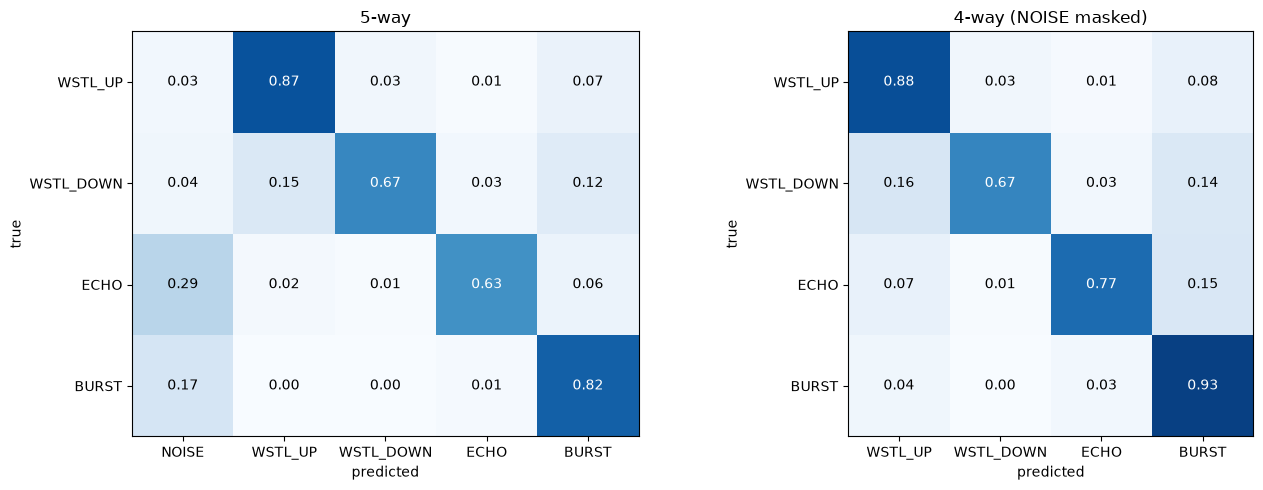

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, cols, title in [(axes[0], "pred5", ["NOISE"] + CLASSES, "5-way"),
                             (axes[1], "pred4", CLASSES, "4-way (NOISE masked)")]:
    cm = pd.crosstab(labels.label, labels[col], normalize="index").reindex(index=CLASSES, columns=cols, fill_value=0)
    ax.imshow(cm.values, cmap="Blues", vmin=0, vmax=1)
    for (r, c), v in np.ndenumerate(cm.values):
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.5 else "black")
    ax.set_xticks(range(len(cols)), cols)
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
plt.tight_layout()